# Simulation de la Ligue des champions

**Objectif :** estimer, pour chacun des 36 clubs, ses chances d'atteindre chaque étape de la compétition (top 8, huitièmes, quarts, ..., victoire finale).

**Méthode :** on simule la compétition entière (phase de ligue puis phase finale) des milliers de fois avec un modèle de buts aléatoire, puis on compte la fréquence de chaque résultat (méthode de Monte-Carlo).

### Lancer le notebook

1. Installer le kernel Julia une seule fois : `using Pkg; Pkg.add("IJulia")`.
2. Ouvrir ce fichier (dans VS Code ou Jupyter) avec le kernel Julia.
3. **Run All.**

Le notebook se suffit à lui-même : la première cellule télécharge le projet depuis GitHub dans un environnement temporaire, sans rien modifier sur la machine. Le premier lancement prend une dizaine de minutes (téléchargement et compilation), les suivants environ 3 minutes.

Toutes les sorties sont déjà enregistrées : on peut lire le compte rendu sans rien lancer.

## 1. Chargement du projet

In [1]:
using Pkg
Pkg.activate(temp = true) # environnement temporaire
Pkg.add(url = "https://github.com/Akashii-touc/SimulationsProjet.jl", rev = "dev")
Pkg.add(["DataFrames", "GLMakie"])

using SimulationsProjet, DataFrames, GLMakie
GLMakie.activate!(inline = true) # graphiques dans le notebook

N = 10000 # nombre de simulations

  Activating new project at `C:\Users\yaya\AppData\Local\Temp\jl_morZOP`
     Cloning git-repo `https://github.com/Akashii-touc/SimulationsProjet.jl`


    Updating git-repo `https://github.com/Akashii-touc/SimulationsProjet.jl`


   Resolving package versions...


   Installed OrderedCollections ────── v2.0.3
   Installed SentinelArrays ────────── v1.4.11
   Installed Missings ──────────────── v1.2.1
   Installed HarfBuzz_jll ──────────── v100.15000.0+0
   Installed LoweredCodeUtils ──────── v3.10.1
   Installed InverseFunctions ──────── v0.1.18


   Installed AdaptiveArrayPools ────── v0.3.12
   Installed Revise ────────────────── v3.18.0


...

   4.2 s  ✓ IntervalArithmetic → IntervalArithmeticMakieExt


   4.7 s  ✓ IntervalSets → IntervalSetsMakieExt


  50.3 s  ✓ GLMakie


   6.4 s  ✓ SimulationsProjet
  101 dependencies successfully precompiled in 224 seconds. 233 already precompiled.
    Updating `C:\Users\yaya\AppData\Local\Temp\jl_morZOP\Project.toml`
  [a93c6f00] + DataFrames v1.8.2
  [e9467ef8] + GLMakie v0.13.16
    Manifest No packages added to or removed from `C:\Users\yaya\AppData\Local\Temp\jl_morZOP\Manifest.toml`


10000

## 2. Données

- `classement_club.csv` : coefficients UEFA (club et pays) des 36 clubs ;
- `matchs.csv` : calendrier des 8 journées de la phase de ligue ;
- `tirs_au_but.csv` : séances de tirs au but jouées et tirs réussis par club.

In [2]:
first(CLASSEMENT, 10)

Row,Club,Pays,Coeff_club,Coeff_pays,Elo
,String,String,Float64,Float64,Int64
1,Bayern,Allemagne,129.5,81.545,2046
2,Arsenal,Angleterre,127.0,103.796,2040
3,RealMadrid,Espagne,122.5,83.243,1972
4,ParisSG,France,121.0,69.153,1956
5,Inter,Italie,115.0,88.589,1946
6,ManCity,Angleterre,106.5,103.796,2028
7,Barcelone,Espagne,106.25,83.243,2024
8,Liverpool,Angleterre,105.0,103.796,1937
9,Dortmund,Allemagne,98.75,81.545,1900


In [3]:
first(CALENDRIER, 5)

Row,Match_1,Match_2,Match_3,Match 4,Match_5,Match_6,Match_7,Match_8
,String,String,String,String,String,String,String,String
1,Brugge - AstonVilla,Lens - Sporting,Fenerbahçe - SlaviaPrague,Shakhtar - Sporting,Bodo/Glimt - LASK,Villarreal - SabahFC,Bodo/Glimt - AtléticoMadrid,ParisSG - Galatasaray
2,AEKAthènes - LASK,SabahFC - SlaviaPrague,SabahFC - Dortmund,Galatasaray - Stuttgart,Galatasaray - AstonVilla,Viking - Feyenoord,Galatasaray - Feyenoord,Bayern - Betis
3,RealMadrid - Inter,Inter - Brugge,ParisSG - Barcelone,Barcelone - AstonVilla,RealMadrid - PSV,Bayern - SlaviaPrague,RealMadrid - LASK,Liverpool - Lens
4,Dortmund - Villarreal,Arsenal - Lille,Liverpool - Villarreal,AtléticoMadrid - Bayern,ManCity - Naples,Barcelone - ManCity,Inter - Liverpool,ManCity - Sporting
5,Porto - ManCity,AtléticoMadrid - ManUnited,ManCity - AEKAthènes,ManUnited - Roma,Arsenal - Dortmund,Roma - Sporting,AstonVilla - Dortmund,Arsenal - SabahFC


In [4]:
first(STATS_TAB, 5)

Row,Club,seances_jouees,seances_gagnees,tirs_tentes,tirs_reussis
,String,Int64,Int64,Int64,Int64
1,Bayern,11,7,55,43
2,Arsenal,13,8,63,53
3,RealMadrid,6,5,27,22
4,ParisSG,13,8,64,52
5,Inter,6,2,31,20


### Force d'un club

Chaque club a un poids $w$, calculé avec ses coefficients UEFA :

$$F = 0.8 \times \text{Coeff}_\text{club} + 0.2 \times \text{Coeff}_\text{pays}, \qquad w = \frac{F - \overline{F}}{\max F - \min F}$$

### Tirs au but

La probabilité de réussir un tir au but est estimée à partir des données du club, ramenée vers 75 % quand il y a peu de tirs :

$$p = \frac{\text{réussis} + 0.75 \times 10}{\text{tentés} + 10}$$

## 3. Modèles de buts

Pour un match entre $A$ (à domicile) et $B$, avec $\Delta = w_A - w_B$ :

$$\lambda_A = \mu \times 1.2 \times e^{\Delta}, \qquad \lambda_B = \mu \times e^{-\Delta}$$

($1.2$ = avantage du terrain, $\mu$ règle le nombre moyen de buts, environ 3 par match.)

| Modèle | Idée | Paramètres par défaut |
|---|---|---|
| `ModelePoisson` | buts indépendants $\sim \mathcal{P}(\lambda)$ | $\mu = 1.25$ |
| `ModelePoissonBivariee` | Poisson + une partie commune $X \sim \mathcal{P}(\lambda_c e^{-|\Delta|})$ aux deux équipes | $\mu = 1$, $\lambda_c = 0.4$ |
| `ModeleBinomialeNegative` | même moyenne que Poisson mais plus dispersé | $\mu = 1.25$, $p = 0.8$ |
| `ModeleDixonColes` | Poisson corrigé sur les petits scores (0-0, 1-0, 0-1, 1-1) | $\mu = 1.25$, $\rho = -0.1$ |

**Loi de Poisson :** $P(X = k) = \dfrac{\lambda^k e^{-\lambda}}{k!}$

**Dixon-Coles :** $P(X = a, Y = b) \propto \tau(a, b)\, P(X = a)\, P(Y = b)$, où $\tau$ modifie seulement les scores 0-0, 1-0, 0-1 et 1-1.

## 4. Déroulement d'une simulation

1. **Phase de ligue :** les 8 journées du calendrier, 3 points par victoire, 1 par nul.
2. **Classement :** les 8 premiers vont en huitièmes, les places 9 à 24 jouent les barrages, les 12 derniers sont éliminés.
3. **Phase finale :** matchs aller-retour (prolongation si égalité, puis tirs au but), finale sur un seul match.

## 5. Résultats avec Dixon-Coles

In [5]:
df = classement_stats(rand(N, ModeleDixonColes(); seed = 1))
show(df, allrows = true, allcols = true)

36×10 DataFrame
 Row │ Club            xPoints  Top8     Top24    Elimine  Huitieme  Quart    Demie    Finale   Vainqueur 
     │ String          Float64  Float64  Float64  Float64  Float64   Float64  Float64  Float64  Float64   
─────┼────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ Bayern            17.62    79.26    99.71     0.29     97.07    75.64    50.95    31.07      17.5
   2 │ Arsenal           17.02    73.39    99.46     0.54     96.89    76.99    54.12    36.21      22.11
   3 │ RealMadrid        16.83    71.82    99.47     0.53     95.64    70.05    44.29    25.71      13.15
   4 │ ParisSG           16.3     64.87    99.06     0.94     93.78    65.63    39.08    20.79      10.06
   5 │ Liverpool         16.3     65.12    99.09     0.91     92.58    61.03    31.47    15.22       6.76
   6 │ Inter             15.88    59.3     98.56     1.44     91.78    61.18    33.92    17.03       8.43
   7 │ ManCity           15.

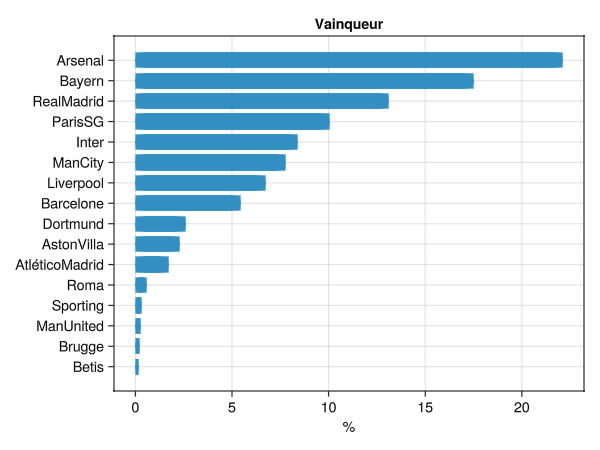

In [6]:
graphique_chances(df)

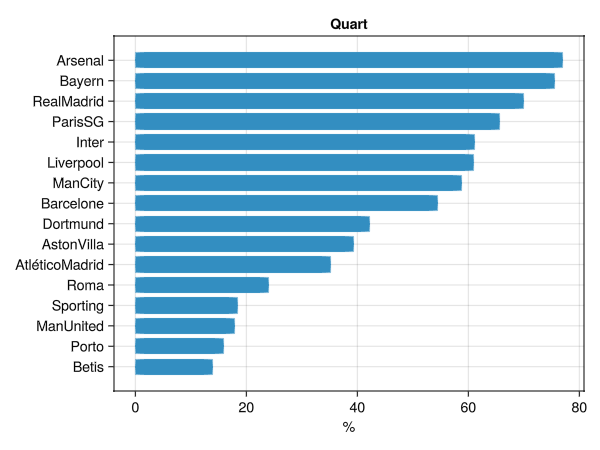

In [7]:
graphique_chances(df; etape = :Quart)

**Lecture du tableau :** `xPoints` = points moyens en phase de ligue ; `Top8`, `Top24`, `Elimine` = probabilité (en %) de finir dans les 8 premiers, dans les 24 premiers ou d'être éliminé après la phase de ligue ; `Huitieme`, ..., `Vainqueur` = probabilité d'atteindre cette étape.

*(Les chiffres peuvent bouger de quelques dixièmes si on relance avec un autre nombre de threads.)*

**Analyse :**

- **Quatre favoris se détachent :** Arsenal (environ 22 % de chances de gagner), le Bayern (environ 17,5 %), le Real Madrid (environ 13 %) et le PSG (environ 10 %). Même le favori gagne moins d'une fois sur quatre : avec des matchs à élimination directe, le hasard pèse beaucoup.
- **Le Bayern fait le plus de points en phase de ligue (17,6 en moyenne), mais Arsenal a plus de chances de gagner.** Arsenal a le poids UEFA le plus élevé, grâce au coefficient du championnat anglais ($F = 122{,}4$ contre $119{,}9$ pour le Bayern). Le Bayern a donc sans doute un calendrier plus facile en phase de ligue. Arsenal réussit aussi mieux ses tirs au but (environ 83 % contre 78 %).
- **Finir dans le top 8 compte beaucoup :** ces clubs vont directement en huitièmes, alors que les places 9 à 24 doivent passer un barrage de plus. Les 8 meilleurs clubs y arrivent dans 55 à 80 % des cas.
- **En bas du classement,** Sabah FC, le LASK et Viking sont éliminés dès la phase de ligue environ 9 fois sur 10.
- Sur le graphique des quarts, l'écart entre les clubs est plus faible : beaucoup de clubs y arrivent souvent, c'est ensuite que les favoris font la différence.

## 6. Comparaison des modèles

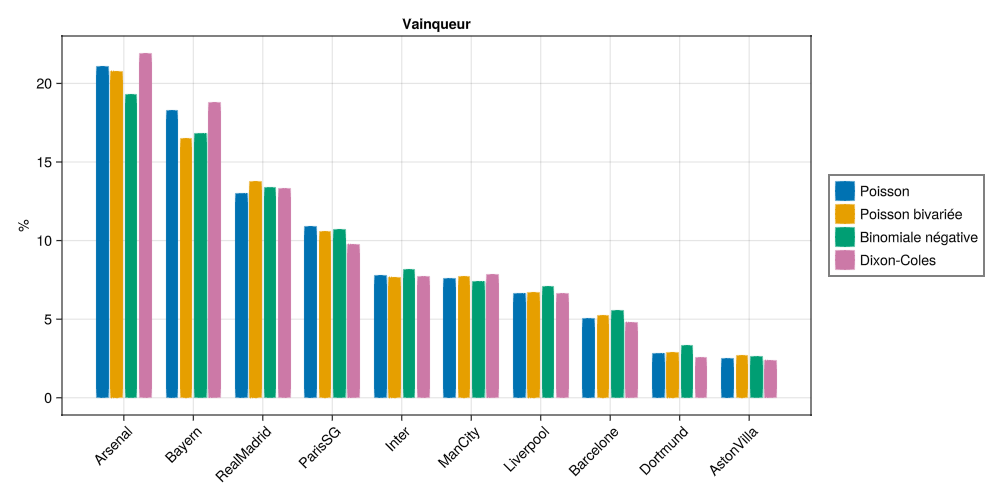

In [8]:
comparaison_modeles(N)

**Analyse :**

- **Les 4 modèles donnent presque le même classement :** Arsenal, Bayern, Real Madrid, PSG, puis un groupe Inter, City, Liverpool. Les différences entre modèles sont de 1 à 3 points au plus.
- La **binomiale négative** donne les favoris un peu moins sûrs (Arsenal environ 19 %) : les scores sont plus dispersés, donc il y a plus de surprises.
- **Dixon-Coles** les avantage un peu (Arsenal environ 22 %, Bayern environ 19 %).
- **Le choix du modèle de buts change donc peu les résultats.**

## 7. Effet de μ (nombre moyen de buts)

In [9]:
for μ in [1.0, 1.25, 1.5]
    d = classement_stats(rand(N, ModeleDixonColes(μ = μ); seed = 1))
    println("μ = $μ : ", first(sort(d, :Vainqueur, rev = true), 3)[:, [:Club, :Vainqueur]])
end

μ = 1.0 : 3×2 DataFrame
 Row │ Club        Vainqueur 
     │ String      Float64   
─────┼───────────────────────
   1 │ Arsenal         20.2
   2 │ Bayern          17.31
   3 │ RealMadrid      13.65


μ = 1.25 : 3×2 DataFrame
 Row │ Club        Vainqueur 
     │ String      Float64   
─────┼───────────────────────
   1 │ Arsenal         22.11
   2 │ Bayern          17.5
   3 │ RealMadrid      13.15


μ = 1.5 : 3×2 DataFrame
 Row │ Club        Vainqueur 
     │ String      Float64   
─────┼───────────────────────
   1 │ Arsenal         21.87
   2 │ Bayern          18.77
   3 │ RealMadrid      13.93


**Analyse :**

- Les trois favoris restent les mêmes quel que soit $\mu$.
- Avec plus de buts, le meilleur club gagne un peu plus souvent, car il y a moins de matchs nuls et moins de tirs au but. Par exemple, le Bayern passe d'environ 17,3 % à 18,8 % quand $\mu$ va de 1 à 1,5.
- Mais l'effet est faible (1 à 2 points), à peine plus grand que la précision de la simulation (voir partie suivante). Le réglage de $\mu$ n'est donc pas critique.

## 8. Nombre de simulations suffisant ?

In [10]:
for n in [1000, 10000, 50000]
    d = classement_stats(rand(n, ModeleDixonColes(); seed = 2))
    println("n = $n : ", first(sort(d, :Vainqueur, rev = true), 3)[:, [:Club, :Vainqueur]])
end

n = 1000 : 3×2 DataFrame
 Row │ Club        Vainqueur 
     │ String      Float64   
─────┼───────────────────────
   1 │ Arsenal          20.1
   2 │ Bayern           15.9
   3 │ RealMadrid       15.0


n = 10000 : 3×2 DataFrame
 Row │ Club        Vainqueur 
     │ String      Float64   
─────┼───────────────────────
   1 │ Arsenal         21.65
   2 │ Bayern          18.01
   3 │ RealMadrid      13.6


n = 50000 : 3×2 DataFrame
 Row │ Club        Vainqueur 
     │ String      Float64   
─────┼───────────────────────
   1 │ Arsenal         21.46
   2 │ Bayern          18.09
   3 │ RealMadrid      13.42


Pour une probabilité $p$ estimée avec $n$ simulations, l'erreur type vaut $\sqrt{p(1-p)/n}$. Pour $p = 0{,}2$ :

| $n$ | erreur type |
|---|---|
| 1 000 | environ 1,3 point |
| 10 000 | environ 0,4 point |
| 50 000 | environ 0,2 point |

**Analyse :** c'est ce qu'on observe. Avec 1 000 simulations, le Bayern est à 15,9 % au lieu d'environ 18 %. Entre 10 000 et 50 000 simulations, les chiffres ne changent presque plus. **10 000 simulations suffisent :** les écarts entre clubs (plusieurs points) sont bien plus grands que l'erreur (environ 0,4 point).

## 9. Conclusion et limites

En simulant 10 000 fois la compétition, on obtient pour chaque club sa probabilité d'atteindre chaque étape. Avec le modèle de Dixon-Coles, **Arsenal est favori (environ 22 %)**, devant le Bayern, le Real Madrid et le PSG.

- Les résultats sont **stables** : ils changent peu avec le modèle de buts ou avec $\mu$, et 10 000 simulations donnent une précision d'environ 0,4 point.
- Même le favori gagne moins d'une fois sur quatre : le format à élimination directe laisse beaucoup de place au hasard.

**Limites :**
- la force d'un club ne change pas pendant la compétition (blessures, forme) ;
- le tirage de la phase finale est simplifié ;
- les paramètres ($\mu$, $ho$, avantage du terrain de 1,2) sont fixés à la main, et non estimés sur de vrais matchs.